# This is a sample Jupyter Notebook

Below is an example of a code cell. 
Put your cursor into the cell and press Shift+Enter to execute it and select the next one, or click 'Run Cell' button.

Press Double Shift to search everywhere for classes, files, tool windows, actions, and settings.

To learn more about Jupyter Notebooks in PyCharm, see [help](https://www.jetbrains.com/help/pycharm/ipython-notebook-support.html).
For an overview of PyCharm, go to Help -> Learn IDE features or refer to [our documentation](https://www.jetbrains.com/help/pycharm/getting-started.html).

In [4]:
with open("../data/imf-dm-export-20260913.csv", encoding="utf-16") as f:
    for i, line in enumerate(f):
        print(repr(line))
        if i > 5:
            break

'"GDP per capita, current prices\n'
' (U.S. dollars per capita)";1980;1981;1982;1983;1984;1985;1986;1987;1988;1989;1990;1991;1992;1993;1994;1995;1996;1997;1998;1999;2000;2001;2002;2003;2004;2005;2006;2007;2008;2009;2010;2011;2012;2013;2014;2015;2016;2017;2018;2019;2020;2021;2022;2023;2024;2025;2026;2027;2028;2029;2030;2031;Estimates start after\n'
';;;;;;;;;;;;;;;;;;;;;;;;;;;;;;;;;;;;;;;;;;;;;;;;;;;;;\n'
';no data;no data;no data;no data;no data;no data;no data;no data;no data;no data;no data;no data;no data;no data;no data;no data;no data;no data;no data;no data;no data;no data;no data;no data;no data;no data;no data;no data;no data;no data;no data;no data;no data;no data;no data;no data;no data;no data;no data;no data;no data;no data;no data;no data;no data;no data;no data;no data;no data;no data;no data;no data;2026\n'
'Afghanistan;no data;no data;no data;no data;no data;no data;no data;no data;no data;no data;no data;no data;no data;no data;no data;no data;no data;no data;no data;n

In [10]:
import pandas as pd
import matplotlib.pyplot as plt

sat_path= "../data/OECD.WISE.WDP,DSD_HSL@DF_HSL_CWB,1.1,filtered,2026-09-13 15-39-22.csv"
sat = pd.read_csv(sat_path)
sat = sat[sat["Measure"] == "Life satisfaction"].dropna(subset=["OBS_VALUE"]).copy()
sat = sat.rename(
    columns={"Reference area": "Country", "TIME_PERIOD": "Year", "OBS_VALUE": "Life_satisfaction"}
)
sat = sat[["Country","Year", "Life_satisfaction"]]

latest_sat = sat.sort_values(by="Year").groupby("Country").tail(1)
print(latest_sat.head())

             Country  Year  Life_satisfaction
2086         Iceland  2018           8.133542
2005       Australia  2020           7.200000
2128          Mexico  2021           8.448711
2035        Colombia  2022           7.920844
2209  United Kingdom  2022           7.450000


In [6]:
import pandas as pd
gdp_path = "../data/imf-dm-export-20260913.csv"
gdp_raw = pd.read_csv(
    gdp_path,
    encoding="utf-16",
    sep=";",
    dtype=str,             
)

gdp_raw = gdp_raw.rename(columns={gdp_raw.columns[0]: "Country"})
gdp_raw = gdp_raw[gdp_raw["Country"].notna()]
year_cols = [c for c in gdp_raw.columns if c.isdigit()]
gdp_long = gdp_raw.melt(
    id_vars="Country", value_vars=year_cols, var_name="Year", value_name="GDP_per_capita"
)

gdp_long["GDP_per_capita"] = (
    gdp_long["GDP_per_capita"]
    .str.strip()                          
    .replace("no data", pd.NA)            
    .str.replace(",", ".", regex=False)  
)
gdp_long["GDP_per_capita"] = pd.to_numeric(gdp_long["GDP_per_capita"], errors="coerce")

gdp_long["Year"] = gdp_long["Year"].astype(int)
gdp_long = gdp_long.dropna(subset=["GDP_per_capita"])

sat = pd.read_csv(sat_path)
sat = sat[sat["Measure"] == "Life satisfaction"].dropna(subset=["OBS_VALUE"]).copy()
sat = sat.rename(
    columns={"Reference area": "Country", "TIME_PERIOD": "Year", "OBS_VALUE": "Life_satisfaction"}
)
sat = sat[["Country","Year", "Life_satisfaction"]]

latest_sat = sat.sort_values(by="Year").groupby("Country").tail(1)

NAME_FIX = {
    "Korea": "Korea, Republic of",
    "Czechia": "Czech Republic",
    "Türkiye": "Türkiye, Republic of",
}
gdp_long["Country"] = gdp_long["Country"].replace({v: k for k, v in NAME_FIX.items()})

merged = latest_sat.merge(gdp_long, on=["Country", "Year"], how="left")
merged = merged.dropna(subset=["GDP_per_capita", "Life_satisfaction"])
merged = merged.sort_values("GDP_per_capita", ascending=False).reset_index(drop=True)

merged.head()


,Country,Year,Life_satisfaction,GDP_per_capita
0,Luxembourg,2025,7.400000,148246.975
1,Ireland,2025,7.600000,130652.363
2,Switzerland,2024,7.700000,108255.920
3,Norway,2025,7.700000,94468.188
4,Iceland,2018,8.133542,77963.129


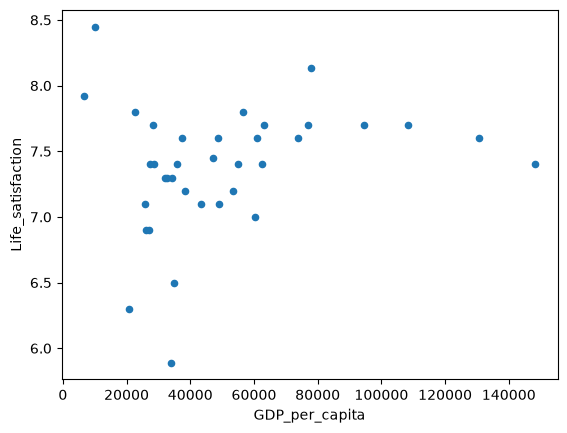

In [7]:
import sklearn.linear_model

merged.plot(kind="scatter", x="GDP_per_capita", y="Life_satisfaction")
plt.show()

In [9]:
import numpy as np
X = np.c_[merged["GDP_per_capita"]]
y = np.c_[merged["Life_satisfaction"]]
model = sklearn.linear_model.LinearRegression()
model.fit(X,y)

new_country =[[22345]]
prediction = model.predict(new_country)
print(f"{prediction[0][0]:.2f}")


7.29
